# 04 · Anomalies and association rules

**Question:** How does CrimeScope identify unusual cross-sectional counts and category co-presence in district reporting profiles?

**Input and scope:** Verified 2024 active feature input and the saved anomaly/rule artifacts from the run selected by `analysis/output/runs/current.json`. A transaction is one eligible administrative district’s 2024 category profile. No event-level records are available here.

In [1]:
from pathlib import Path
import hashlib, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "analysis/output/runs/current.json").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("CrimeScope root not found; open from the repo root or notebooks folder. See docs/handoff.md.")
sys.path.insert(0, str(ROOT / "analysis/src"))

def read_json(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Required artifact missing: {path}. Restore the analysis handoff described in docs/handoff.md.")
    return json.loads(path.read_text(encoding="utf-8"))

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

release_pointer = read_json(ROOT / "data/serving/current.json")
release = read_json(ROOT / release_pointer["release_path"] / "release_manifest.json")
run_pointer = read_json(ROOT / "analysis/output/runs/current.json")
run_manifest_path = ROOT / run_pointer["manifest"]
run = read_json(run_manifest_path)
run_dir = run_manifest_path.parent
feature_path = ROOT / run["feature_input"]["path"]
for path, expected, label in [(feature_path, run["feature_input"]["sha256"], "active feature input")]:
    if not path.is_file():
        raise FileNotFoundError(f"Missing {label}: {path}. Restore the local analysis handoff described in docs/handoff.md.")
    assert sha256(path) == expected, f"{label} hash mismatch at {path}; restore the manifest-selected artifact."
assert run_pointer["run_id"] == run["run_id"]

def artifact(relative):
    path = run_dir / relative
    expected = run["artifacts"].get(relative)
    if expected is None:
        raise KeyError(f"Active run manifest does not list expected artifact {relative}")
    if not path.is_file():
        raise FileNotFoundError(f"Active run artifact missing: {path}. Restore the active analysis handoff described in docs/handoff.md.")
    assert sha256(path) == expected, f"Saved artifact hash mismatch: {path}"
    return path

print(f"Run: {run['run_id']} | cohort: {run['feature_input']['regions']} eligible administrative districts × {run['feature_input']['features']} categories")

Run: ncrb-national-2024-admin-log1p-zscore-20261107-v4 | cohort: 774 eligible administrative districts × 131 categories


## Cross-sectional z-scores use the sample standard deviation

The active implementation computes one mean and sample standard deviation (`ddof=1`) per category across the 2024 reporting-unit cohort, then applies `z = (x − mean) / s`. The configured flag threshold is `|z| ≥ 2.5`. This notebook uses the saved artifact for examples and calls the in-memory implementation to verify their values; it writes no analysis artifacts.

In [2]:
from crimescope_analysis.methods.anomaly import load_feature_matrix, cross_sectional_anomalies, _std

anomaly_relative = run["methods"]["anomalies"]["artifact"]
anomaly_path = artifact(anomaly_relative)
saved_anomalies = json.loads(anomaly_path.read_text(encoding="utf-8"))
threshold = run["parameters"]["anomaly"]["z_threshold"]
feature_rows = load_feature_matrix(feature_path)
assert saved_anomalies["year"] == 2024 and threshold == 2.5
recomputed = cross_sectional_anomalies(feature_rows, 2024, z_threshold=threshold)

rare = next(a for a in saved_anomalies["cross_sectional"] if a["region"] == "Satara" and a["category"] == "Abetment outside India for offence in India")
high_volume = next(a for a in saved_anomalies["cross_sectional"] if a["region"] == "North-West" and a["state_name"] == "Delhi" and "Other Thefts" in a["category"])
examples = pd.DataFrame([rare, high_volume])[['year','state_name','region','category','value','category_mean','category_std','z_score','direction']]
display(examples)

def verify_z(example):
    values = [r["total"] for r in feature_rows if r["year"] == 2024 and r["category"] == example["category"]]
    mean = sum(values) / len(values)
    sample_std = _std(values)  # active module's sample-standard-deviation helper
    value = next(r["total"] for r in feature_rows if r["year"] == 2024 and r["region_id"] == example["region_id"] and r["category"] == example["category"])
    return len(values), mean, sample_std, (value - mean) / sample_std

verification = pd.DataFrame([{"region": x["region"], "category sample size": verify_z(x)[0], "computed mean": verify_z(x)[1],
                              "computed sample std": verify_z(x)[2], "computed z": verify_z(x)[3], "saved z": x["z_score"]}
                             for x in (rare, high_volume)])
display(verification.round(5))
for example in (rare, high_volume):
    check = next(a for a in recomputed if a["region_id"] == example["region_id"] and a["category"] == example["category"])
    assert check["value"] == example["value"] and np.isclose(check["z_score"], example["z_score"], atol=.0001)
assert rare["value"] == 1 and round(rare["z_score"], 2) == 27.78
assert high_volume["value"] == 13156 and round(high_volume["z_score"], 2) == 10.89

,year,state_name,region,category,value,category_mean,category_std,z_score,direction
0,2024,Maharashtra,Satara,Abetment outside India for offence in India,1,0.0,0.04,27.7849,high
1,2024,Delhi,North-West,g) Other Thefts/305/307 BNS/IPC),13156,318.9,1179.06,10.8875,high


,region,category sample size,computed mean,computed sample std,computed z,saved z
0,Satara,774,0.00129,0.03594,27.78491,27.7849
1,North-West,774,318.89793,1179.06442,10.88753,10.8875


Satara’s single recorded case is extreme relative to a category that is zero in nearly every district, so its z-score is large even though the raw count is one. A z-score flags unusualness within a category; it does not imply severity or indicate a data error.

## Association rules from district profiles

The runner defines an item as a category with at least 10 reported cases in a district. Districts whose profile has no items at that cutoff do not form transactions. The saved Apriori settings also require support ≥0.15, confidence ≥0.60, maximum itemset size 2, and lift ≥1.05.

In [3]:
from crimescope_analysis.methods.association import load_feature_matrix as load_association_rows, build_transactions, apriori

association_relative = run["methods"]["association"]["artifact"]
association_path = artifact(association_relative)
saved_rules = json.loads(association_path.read_text(encoding="utf-8"))
params = run["parameters"]["association"]
association_rows = load_association_rows(feature_path)
transactions = build_transactions(association_rows, 2024, min_cases=params["min_cases"])
cohort_districts = len({r["region_id"] for r in association_rows})
excluded_empty_profiles = cohort_districts - len(transactions)
assert len(transactions) == saved_rules["n_transactions"] == run["methods"]["association"]["transactions"] == 739
assert excluded_empty_profiles == run["exclusions"]["association_districts_without_items_at_min_cases"] == 35

recomputed_rules = apriori(transactions, min_support=params["min_support"], min_confidence=params["min_confidence"],
                           max_itemset_size=params["max_itemset_size"], min_lift=params["min_lift"])
assert recomputed_rules["n_rules"] == saved_rules["n_rules"] == run["methods"]["association"]["rules"] == 697

rule = next(r for r in saved_rules["rules"] if r["antecedent"] == ["Stalking"] and r["consequent"] == ["Arson,326 & 327 BNS/Section 435,436 & 438 IPC)"])
antecedent, consequent = rule["antecedent"][0], rule["consequent"][0]
n = len(transactions)
n_antecedent = sum(antecedent in t for t in transactions)
n_consequent = sum(consequent in t for t in transactions)
n_joint = sum(antecedent in t and consequent in t for t in transactions)
support = n_joint / n
confidence = n_joint / n_antecedent
consequent_prevalence = n_consequent / n
lift = confidence / consequent_prevalence
rule_metrics = pd.DataFrame([{
    "saved rule": f"{antecedent} -> {consequent}", "transactions N": n,
    "antecedent count": n_antecedent, "consequent count": n_consequent, "joint count": n_joint,
    "support = joint / N": support, "confidence = joint / antecedent": confidence,
    "consequent prevalence": consequent_prevalence, "lift = confidence / prevalence": lift,
}])
display(rule_metrics.round(4))
assert (n_antecedent, n_consequent, n_joint) == (184, 218, 123)
assert np.isclose(support, rule["support"], atol=.0001)
assert np.isclose(confidence, rule["confidence"], atol=.0001)
assert np.isclose(lift, rule["lift"], atol=.0001)

,saved rule,transactions N,antecedent count,consequent count,joint count,support = joint / N,confidence = joint / antecedent,consequent prevalence,lift = confidence / prevalence
0,"Stalking -> Arson,326 & 327 BNS/Section 435,43...",739,184,218,123,0.1664,0.6685,0.295,2.2661


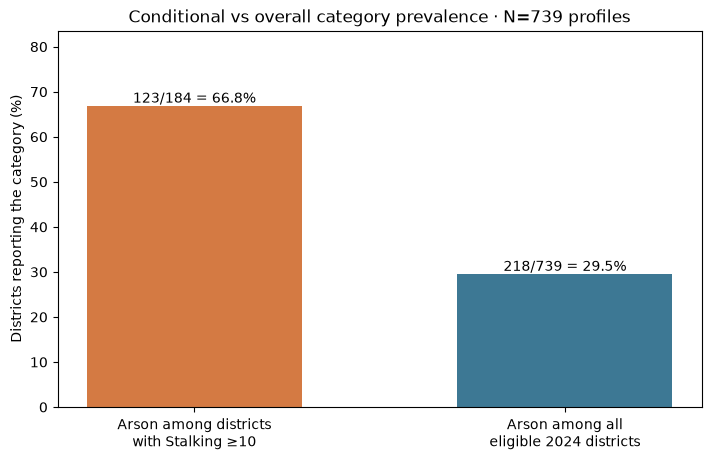

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.5), constrained_layout=True)
labels = ["Arson among districts\nwith Stalking ≥10", "Arson among all\neligible 2024 districts"]
values = [confidence * 100, consequent_prevalence * 100]
bars = ax.bar(labels, values, color=["#d47a43", "#3d7894"], width=.58)
ax.set_ylabel("Districts reporting the category (%)")
ax.set_title("Conditional vs overall category prevalence · N=739 profiles")
ax.set_ylim(0, max(values) * 1.25)
for bar, count, denom, value in zip(bars, [n_joint, n_consequent], [n_antecedent, n], values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f"{count}/{denom} = {value:.1f}%", ha="center", va="bottom")
plt.show()

### Interpretation and limitations

Support is the share of transactions containing both items; confidence is the share of Stalking-item transactions that also contain the Arson item; lift compares that conditional prevalence with Arson’s overall prevalence. The unit of analysis is one district’s 2024 reporting profile, and each item means the district reported at least 10 cases in that category.

These measures describe category co-presence across district profiles. They do not show that events occurred together, that one category caused another, or that a district is unsafe. The 35 empty profiles are excluded from the 739-transaction rule denominator, but remain part of the original 774-district analytical cohort.